In [52]:
#===================================================================================================================
# Deep Learning-Based Predictive Maintenance and Anomaly Detection for Industrial Robotic Systems Using Sensor Data
#===================================================================================================================

In [53]:
# Phase - 1

In [54]:
import pandas as pd

df = pd.read_csv(r"E:\Learning\MTech_Data science and ML_July2024\Semester 4\ai4i2020.csv")

df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [55]:
df.shape

(10000, 14)

In [56]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [57]:
df["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [58]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


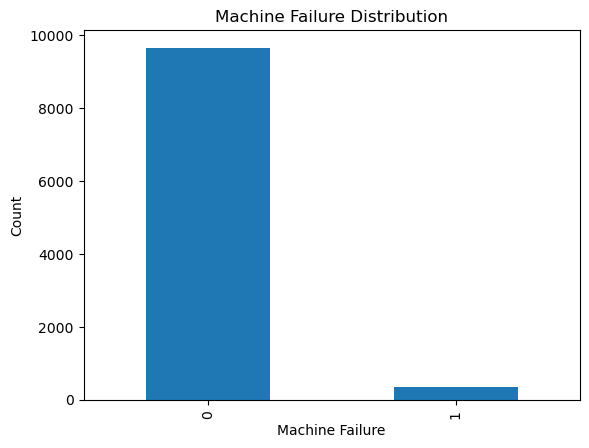

In [59]:
import matplotlib.pyplot as plt

df["Machine failure"].value_counts().plot(kind="bar")

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure")
plt.ylabel("Count")

plt.show()

In [60]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

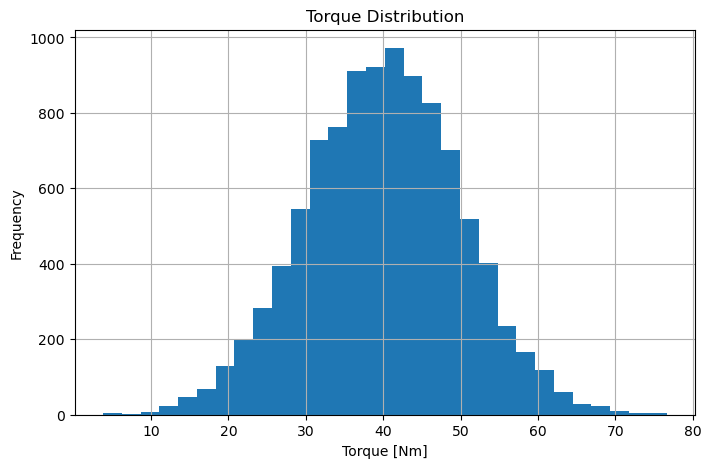

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
df["Torque [Nm]"].hist(bins=30)

plt.title("Torque Distribution")
plt.xlabel("Torque [Nm]")
plt.ylabel("Frequency")

plt.show()

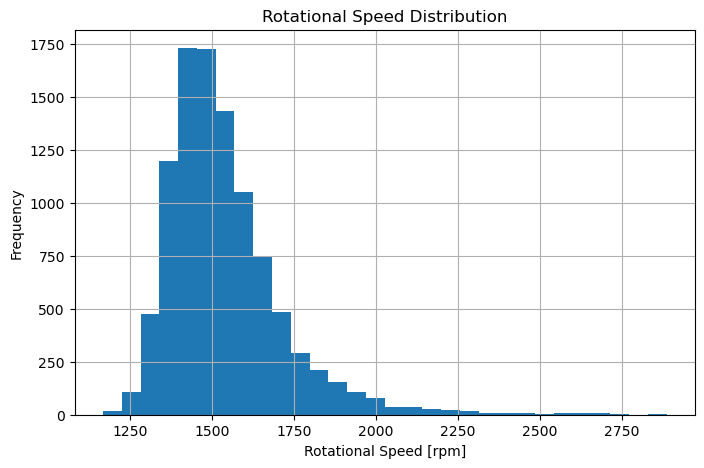

In [62]:
plt.figure(figsize=(8,5))
df["Rotational speed [rpm]"].hist(bins=30)

plt.title("Rotational Speed Distribution")
plt.xlabel("Rotational Speed [rpm]")
plt.ylabel("Frequency")

plt.show()

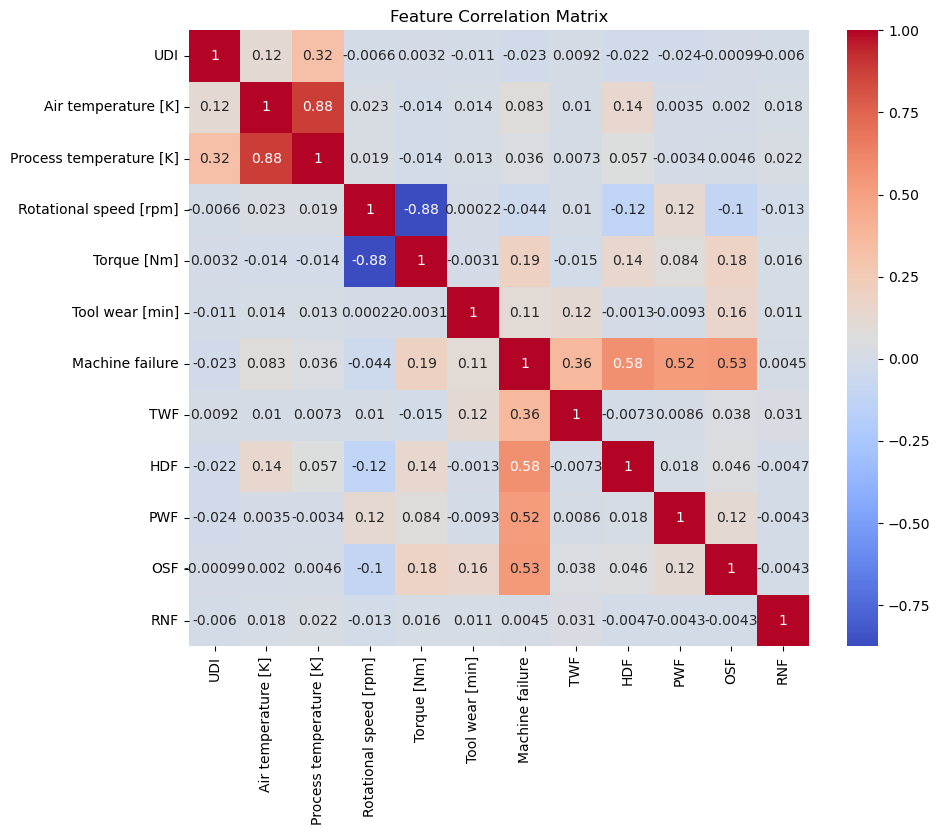

In [63]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap="coolwarm")

plt.title("Feature Correlation Matrix")
plt.show()

In [64]:
from sklearn.preprocessing import LabelEncoder

df_model = df.copy()

le = LabelEncoder()
df_model['Type'] = le.fit_transform(df_model['Type'])

df_model.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,2,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,1,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,1,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,1,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,1,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [65]:
X = df_model.drop(
    columns=[
        'UDI',
        'Product ID',
        'Machine failure'
    ]
)

y = df_model['Machine failure']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (10000, 11)
Target Shape: (10000,)


In [66]:
# Train Test Split

In [67]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (8000, 11)
Testing : (2000, 11)


In [68]:
# ============================================
# RANDOM FOREST Training
# ============================================

In [69]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

print("Random Forest Training Completed")

Random Forest Training Completed


In [70]:
y_pred = rf.predict(X_test)

In [71]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", round(accuracy,4))
print("Precision:", round(precision,4))
print("Recall   :", round(recall,4))
print("F1 Score :", round(f1,4))

Accuracy : 0.999
Precision: 1.0
Recall   : 0.9706
F1 Score : 0.9851


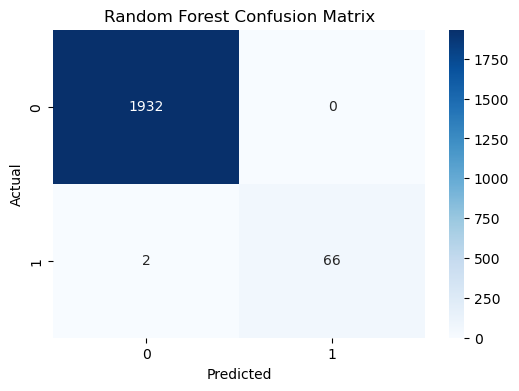

In [72]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [73]:
# ============================================
# RANDOM FOREST - Re train
# ============================================

In [74]:
X = df_model.drop(
    columns=[
        'UDI',
        'Product ID',
        'Machine failure',
        'TWF',
        'HDF',
        'PWF',
        'OSF',
        'RNF'
    ]
)

In [75]:
print(X.columns)
print(X.shape)

Index(['Type', 'Air temperature [K]', 'Process temperature [K]',
       'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]'],
      dtype='object')
(10000, 6)


In [76]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(8000, 6)
(2000, 6)


In [77]:
from sklearn.ensemble import RandomForestClassifier

rf2 = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf2.fit(X_train, y_train)

print("Training Complete")

Training Complete


In [78]:
y_pred2 = rf2.predict(X_test)

In [79]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

accuracy = accuracy_score(y_test, y_pred2)
precision = precision_score(y_test, y_pred2)
recall = recall_score(y_test, y_pred2)
f1 = f1_score(y_test, y_pred2)

print("Accuracy :", round(accuracy,4))
print("Precision:", round(precision,4))
print("Recall   :", round(recall,4))
print("F1 Score :", round(f1,4))

Accuracy : 0.985
Precision: 0.88
Recall   : 0.6471
F1 Score : 0.7458


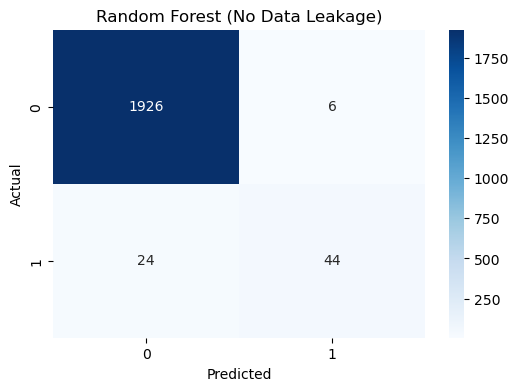

In [80]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred2)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Random Forest (No Data Leakage)")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [81]:
# ============================================
# XGBoost Training
# ============================================

In [82]:
import xgboost

In [83]:
!pip install xgboost

In [84]:
from xgboost import XGBClassifier

In [85]:
X_train_xgb = X_train.copy()
X_test_xgb = X_test.copy()

X_train_xgb.columns = [
    col.replace('[','').replace(']','')
    for col in X_train_xgb.columns
]

X_test_xgb.columns = [
    col.replace('[','').replace(']','')
    for col in X_test_xgb.columns
]

print(X_train_xgb.columns)

Index(['Type', 'Air temperature K', 'Process temperature K',
       'Rotational speed rpm', 'Torque Nm', 'Tool wear min'],
      dtype='object')


In [86]:
xgb = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    random_state=42
)

xgb.fit(X_train_xgb, y_train)

print("XGBoost Training Completed")

XGBoost Training Completed


In [87]:
y_pred_xgb = xgb.predict(X_test_xgb)

In [88]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

accuracy = accuracy_score(y_test, y_pred_xgb)
precision = precision_score(y_test, y_pred_xgb)
recall = recall_score(y_test, y_pred_xgb)
f1 = f1_score(y_test, y_pred_xgb)

print("Accuracy :", round(accuracy,4))
print("Precision:", round(precision,4))
print("Recall   :", round(recall,4))
print("F1 Score :", round(f1,4))

Accuracy : 0.9895
Precision: 0.9273
Recall   : 0.75
F1 Score : 0.8293


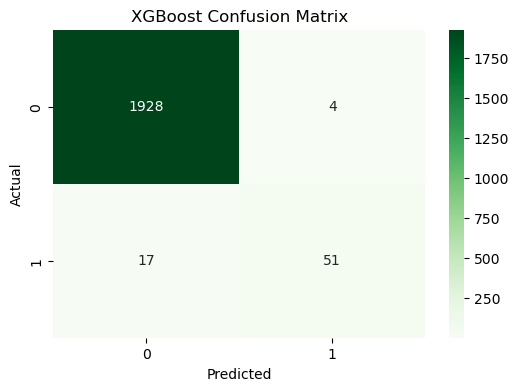

In [89]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [90]:
# ==========================================
# FAILURE TYPE ANALYSIS
# ==========================================

In [91]:
import pandas as pd

feature_importance = pd.DataFrame({
    'Feature': X_train_xgb.columns,
    'Importance': xgb.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

                 Feature  Importance
4              Torque Nm    0.298231
3   Rotational speed rpm    0.206347
5          Tool wear min    0.184526
1      Air temperature K    0.147219
2  Process temperature K    0.101933
0                   Type    0.061744


In [92]:
df['Torque_Bin'] = pd.cut(
    df['Torque [Nm]'],
    bins=[0,20,40,60,80],
    labels=['0-20','20-40','40-60','60-80']
)

torque_analysis = pd.crosstab(
    df['Torque_Bin'],
    df['Machine failure']
)

torque_analysis['Failure_Rate_%'] = (
    torque_analysis[1] /
    (torque_analysis[0] + torque_analysis[1])
) * 100

print(torque_analysis)

Machine failure     0    1  Failure_Rate_%
Torque_Bin                                
0-20              199   34       14.592275
20-40            4726   28        0.588978
40-60            4599  178        3.726188
60-80             137   99       41.949153


In [93]:
df['RPM_Bin'] = pd.cut(
    df['Rotational speed [rpm]'],
    bins=[1100,1400,1700,2000,3000],
    labels=['1100-1400','1400-1700','1700-2000','2000-3000']
)

rpm_analysis = pd.crosstab(
    df['RPM_Bin'],
    df['Machine failure']
)

rpm_analysis['Failure_Rate_%'] = (
    rpm_analysis[1] /
    (rpm_analysis[0] + rpm_analysis[1])
) * 100

print(rpm_analysis)

Machine failure     0    1  Failure_Rate_%
RPM_Bin                                   
1100-1400        1633  237       12.673797
1400-1700        6728   62        0.913108
1700-2000        1107    7        0.628366
2000-3000         193   33       14.601770


In [94]:
df['ToolWear_Bin'] = pd.cut(
    df['Tool wear [min]'],
    bins=[0,50,100,150,200,260],
    labels=['0-50','50-100','100-150','150-200','200-260']
)

toolwear_analysis = pd.crosstab(
    df['ToolWear_Bin'],
    df['Machine failure']
)

toolwear_analysis['Failure_Rate_%'] = (
    toolwear_analysis[1] /
    (toolwear_analysis[0] + toolwear_analysis[1])
) * 100

print(toolwear_analysis)

Machine failure     0    1  Failure_Rate_%
ToolWear_Bin                              
0-50             2227   49        2.152900
50-100           2218   53        2.333774
100-150          2245   50        2.178649
150-200          2210   66        2.899824
200-260           644  118       15.485564


In [95]:
high_torque = df[df['Torque [Nm]'] > 60]

print("Total Samples =", len(high_torque))

print("TWF =", high_torque['TWF'].sum())
print("HDF =", high_torque['HDF'].sum())
print("PWF =", high_torque['PWF'].sum())
print("OSF =", high_torque['OSF'].sum())
print("RNF =", high_torque['RNF'].sum())

Total Samples = 236
TWF = 2
HDF = 19
PWF = 59
OSF = 38
RNF = 1


In [96]:
high_wear = df[df['Tool wear [min]'] > 200]

print("TWF =", high_wear['TWF'].sum())
print("HDF =", high_wear['HDF'].sum())
print("PWF =", high_wear['PWF'].sum())
print("OSF =", high_wear['OSF'].sum())
print("RNF =", high_wear['RNF'].sum())

TWF = 44
HDF = 9
PWF = 8
OSF = 68
RNF = 2


In [97]:
low_rpm = df[df['Rotational speed [rpm]'] < 1400]

print("TWF =", low_rpm['TWF'].sum())
print("HDF =", low_rpm['HDF'].sum())
print("PWF =", low_rpm['PWF'].sum())
print("OSF =", low_rpm['OSF'].sum())
print("RNF =", low_rpm['RNF'].sum())

TWF = 9
HDF = 115
PWF = 49
OSF = 81
RNF = 4


In [98]:
high_rpm = df[df['Rotational speed [rpm]'] > 2000]

print("TWF =", high_rpm['TWF'].sum())
print("HDF =", high_rpm['HDF'].sum())
print("PWF =", high_rpm['PWF'].sum())
print("OSF =", high_rpm['OSF'].sum())
print("RNF =", high_rpm['RNF'].sum())

TWF = 2
HDF = 0
PWF = 31
OSF = 0
RNF = 0


In [99]:
# ==========================================
# PHASE-1 LIVE PREDICTIVE MAINTENANCE DEMO
# ==========================================

import pandas as pd

print("="*60)
print("PHASE-1 PREDICTIVE MAINTENANCE DEMO")
print("="*60)

print("\nEnter sensor values:\n")

# ---- User Inputs ----
type_input = input("Type (L/M/H): ").upper()

air_temp = float(input("Air Temperature (K): "))
process_temp = float(input("Process Temperature (K): "))
rpm = float(input("Rotational Speed (rpm): "))
torque = float(input("Torque (Nm): "))
tool_wear = float(input("Tool Wear (min): "))

# Encode Type
type_map = {
    'L': 0,
    'M': 1,
    'H': 2
}

sample = pd.DataFrame({
    'Type':[type_map[type_input]],
    'Air temperature K':[air_temp],
    'Process temperature K':[process_temp],
    'Rotational speed rpm':[rpm],
    'Torque Nm':[torque],
    'Tool wear min':[tool_wear]
})

# Prediction
prediction = xgb.predict(sample)[0]
probability = xgb.predict_proba(sample)[0][1]

print("\n" + "="*60)
print("RESULT")
print("="*60)

if prediction == 1:
    print("🔴 MACHINE FAILURE PREDICTED")
else:
    print("🟢 MACHINE IS HEALTHY")

print(f"\nFailure Probability : {probability*100:.2f}%")

print("\nMost Influential Features (from Phase-1 Analysis)")
print("----------------------------------------")
print("1. Torque")
print("2. Rotational Speed")
print("3. Tool Wear")

print("\nModel Used : XGBoost")
print("Dataset : AI4I 2020")
print("Failure Indicators : REMOVED")
print("Prediction based only on operational sensor data.")

print("="*60)

PHASE-1 PREDICTIVE MAINTENANCE DEMO

Enter sensor values:



Type (L/M/H):  M
Air Temperature (K):  60
Process Temperature (K):  300
Rotational Speed (rpm):  400
Torque (Nm):  350
Tool Wear (min):  20



RESULT
🔴 MACHINE FAILURE PREDICTED

Failure Probability : 78.38%

Most Influential Features (from Phase-1 Analysis)
----------------------------------------
1. Torque
2. Rotational Speed
3. Tool Wear

Model Used : XGBoost
Dataset : AI4I 2020
Failure Indicators : REMOVED
Prediction based only on operational sensor data.


In [155]:
####################################################
# PHASE 2 - HYPERPARAMETER TUNING
####################################################

In [157]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier

In [159]:
param_grid = {

    'max_depth':[3,5,7],

    'learning_rate':[0.01,0.1,0.2],

    'n_estimators':[100,200,300],

    'subsample':[0.8,1.0],

    'colsample_bytree':[0.8,1.0]

}

In [167]:
# Rename columns to remove special characters
X_train.columns = [
    "Type",
    "Air_temperature_K",
    "Process_temperature_K",
    "Rotational_speed_rpm",
    "Torque_Nm",
    "Tool_wear_min"
]

X_test.columns = X_train.columns

print(X_train.columns)

Index(['Type', 'Air_temperature_K', 'Process_temperature_K',
       'Rotational_speed_rpm', 'Torque_Nm', 'Tool_wear_min'],
      dtype='object')


In [169]:
grid = GridSearchCV(

    estimator=XGBClassifier(

        random_state=42,

        eval_metric='logloss'

    ),

    param_grid=param_grid,

    scoring='f1',

    cv=5,

    n_jobs=-1,

    verbose=2

)

In [171]:
grid.fit(X_train, y_train)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False,
                                     eval_metric='logloss', feature_types=None,
                                     feature_weights=None, gamma=None,
                                     grow_policy=None, importance_type=None,
                                     interaction_constraint...
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.8, 1.0],
                         'learning_rate': [0.01, 0.1, 0.2],
                         'max_depth': [3, 5, 7],
                         'n_estimators': [100, 200, 300],
                         'subsample': [0.8, 1.0]},
             scoring='f1', verbose=2)

In [173]:
print(grid.best_params_)

{'colsample_bytree': 1.0, 'learning_rate': 0.2, 'max_depth': 7, 'n_estimators': 200, 'subsample': 0.8}


In [175]:
print(grid.best_score_)

0.745400889222626


In [177]:
best_model = grid.best_estimator_

In [179]:
y_pred = best_model.predict(X_test)

In [181]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", round(accuracy,4))
print("Precision:", round(precision,4))
print("Recall   :", round(recall,4))
print("F1 Score :", round(f1,4))

Accuracy : 0.9855
Precision: 0.8545
Recall   : 0.6912
F1 Score : 0.7642


In [183]:
#Hyperparameter tuning was investigated but did not improve the baseline

In [185]:
#Calculate the class weight

In [187]:
# Calculate class imbalance ratio

negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

print("Negative samples :", negative)
print("Positive samples :", positive)
print("Scale Pos Weight :", round(scale_pos_weight,2))

Negative samples : 7729
Positive samples : 271
Scale Pos Weight : 28.52


In [189]:
from xgboost import XGBClassifier

xgb_weighted = XGBClassifier(
    random_state=42,
    eval_metric='logloss',
    scale_pos_weight=scale_pos_weight
)

xgb_weighted.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [191]:
y_pred_weighted = xgb_weighted.predict(X_test)

In [193]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

accuracy = accuracy_score(y_test, y_pred_weighted)
precision = precision_score(y_test, y_pred_weighted)
recall = recall_score(y_test, y_pred_weighted)
f1 = f1_score(y_test, y_pred_weighted)

print("Accuracy :", round(accuracy,4))
print("Precision:", round(precision,4))
print("Recall   :", round(recall,4))
print("F1 Score :", round(f1,4))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred_weighted))

Accuracy : 0.9845
Precision: 0.7681
Recall   : 0.7794
F1 Score : 0.7737

Confusion Matrix
[[1916   16]
 [  15   53]]


In [195]:
%who

GridSearchCV	 LabelEncoder	 RandomForestClassifier	 X	 XGBClassifier	 X_test	 X_test_xgb	 X_train	 X_train_xgb	 
accuracy	 accuracy_score	 air_temp	 best_model	 cm	 confusion_matrix	 dataframe_columns	 dataframe_hash	 df	 
df_model	 dtypes_str	 f1	 f1_score	 feature_importance	 get_dataframes	 getpass	 grid	 hashlib	 
high_rpm	 high_torque	 high_wear	 import_pandas_safely	 is_data_frame	 json	 le	 low_rpm	 negative	 
param_grid	 pd	 plt	 positive	 precision	 precision_score	 prediction	 probability	 process_temp	 
recall	 recall_score	 rf	 rf2	 rpm	 rpm_analysis	 sample	 scale_pos_weight	 sns	 
tool_wear	 toolwear_analysis	 torque	 torque_analysis	 train_test_split	 type_input	 type_map	 xgb	 xgb_weighted	 
xgboost	 y	 y_pred	 y_pred2	 y_pred_weighted	 y_pred_xgb	 y_test	 y_train	 


In [199]:
print(X_test_xgb.columns)

Index(['Type', 'Air temperature K', 'Process temperature K',
       'Rotational speed rpm', 'Torque Nm', 'Tool wear min'],
      dtype='object')


In [201]:
y_pred_xgb = xgb.predict(X_test_xgb)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy :", round(accuracy_score(y_test, y_pred_xgb),4))
print("Precision:", round(precision_score(y_test, y_pred_xgb),4))
print("Recall   :", round(recall_score(y_test, y_pred_xgb),4))
print("F1 Score :", round(f1_score(y_test, y_pred_xgb),4))

Accuracy : 0.9895
Precision: 0.9273
Recall   : 0.75
F1 Score : 0.8293


In [203]:
import numpy as np
from sklearn.metrics import f1_score

# Get probabilities from original Phase 1 model
y_prob = xgb.predict_proba(X_test_xgb)[:, 1]

best_threshold = 0
best_f1 = 0

print("Threshold\tF1 Score")
print("-------------------------")

for threshold in np.arange(0.10, 0.91, 0.05):

    y_pred_new = (y_prob >= threshold).astype(int)

    f1 = f1_score(y_test, y_pred_new)

    print(f"{threshold:.2f}\t\t{f1:.4f}")

    if f1 > best_f1:
        best_f1 = f1
        best_threshold = threshold

print("\n==========================")
print("Best Threshold :", best_threshold)
print("Best F1 Score  :", round(best_f1,4))

Threshold	F1 Score
-------------------------
0.10		0.6203
0.15		0.6790
0.20		0.7285
0.25		0.7714
0.30		0.7910
0.35		0.8217
0.40		0.8346
0.45		0.8387
0.50		0.8293
0.55		0.7899
0.60		0.7863
0.65		0.7321
0.70		0.7091
0.75		0.6981
0.80		0.5684
0.85		0.4889
0.90		0.3415

Best Threshold : 0.45000000000000007
Best F1 Score  : 0.8387


In [205]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Final prediction using optimized threshold
y_pred_final = (y_prob >= 0.45).astype(int)

print("Accuracy :", round(accuracy_score(y_test, y_pred_final),4))
print("Precision:", round(precision_score(y_test, y_pred_final),4))
print("Recall   :", round(recall_score(y_test, y_pred_final),4))
print("F1 Score :", round(f1_score(y_test, y_pred_final),4))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred_final))

Accuracy : 0.99
Precision: 0.9286
Recall   : 0.7647
F1 Score : 0.8387

Confusion Matrix
[[1928    4]
 [  16   52]]


In [209]:
#Feature Ablation testing - by removing Torque

In [211]:
X_train_ablation = X_train_xgb.copy()
X_test_ablation = X_test_xgb.copy()

In [215]:
#Remove Torque
X_train_drop = X_train_ablation.drop(columns=['Torque Nm'])
X_test_drop = X_test_ablation.drop(columns=['Torque Nm'])

In [217]:
#Train fresh XGBoost
from xgboost import XGBClassifier

xgb_drop = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

xgb_drop.fit(X_train_drop, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [219]:
#Predict probability
y_prob_drop = xgb_drop.predict_proba(X_test_drop)[:,1]

In [221]:
#Use optimized threshold
y_pred_drop = (y_prob_drop >= 0.45).astype(int)

In [223]:
#calculate metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy :", round(accuracy_score(y_test,y_pred_drop),4))
print("Precision:", round(precision_score(y_test,y_pred_drop),4))
print("Recall :", round(recall_score(y_test,y_pred_drop),4))
print("F1 :", round(f1_score(y_test,y_pred_drop),4))

Accuracy : 0.9765
Precision: 0.6909
Recall : 0.5588
F1 : 0.6179


In [225]:
#Conclusion from testing:
#Removing Torque caused
#F1 Score: 83.87% → 61.79% (↓ 22.08 percentage points)
#Precision dropped significantly.
#Recall also dropped significantly.

#This is a major performance degradation.

#Engineering Conclusion:
#Torque is a critical operational sensor for machine failure prediction.
#Removing torque information significantly reduces the model's ability to correctly identify failures.

In [227]:
# Coding for automatically removing feature one by one and retrains XGBoost

In [229]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

features = [
    'Type',
    'Air temperature K',
    'Process temperature K',
    'Rotational speed rpm',
    'Torque Nm',
    'Tool wear min'
]

results = []

for feature in features:

    # Remove one feature
    X_train_temp = X_train_xgb.drop(columns=[feature])
    X_test_temp = X_test_xgb.drop(columns=[feature])

    # Train model
    model = XGBClassifier(
        random_state=42,
        eval_metric='logloss'
    )

    model.fit(X_train_temp, y_train)

    # Predict probabilities
    y_prob = model.predict_proba(X_test_temp)[:,1]

    # Use optimized threshold
    y_pred = (y_prob >= 0.45).astype(int)

    # Metrics
    accuracy = accuracy_score(y_test,y_pred)
    precision = precision_score(y_test,y_pred)
    recall = recall_score(y_test,y_pred)
    f1 = f1_score(y_test,y_pred)

    results.append([
        feature,
        round(accuracy,4),
        round(precision,4),
        round(recall,4),
        round(f1,4)
    ])

ablation_results = pd.DataFrame(
    results,
    columns=[
        "Removed Feature",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
)

ablation_results

,Removed Feature,Accuracy,Precision,Recall,F1 Score
0,Type,0.9835,0.7966,0.6912,0.7402
1,Air temperature K,0.9725,0.6585,0.3971,0.4954
2,Process temperature K,0.9755,0.6939,0.5000,0.5812
3,Rotational speed rpm,0.9730,0.6250,0.5147,0.5645
4,Torque Nm,0.9765,0.6909,0.5588,0.6179
5,Tool wear min,0.9780,0.7609,0.5147,0.6140


In [233]:
#################################
#SHAP Explainability
#################################

In [237]:
pip install shap

INFO: pip is looking at multiple versions of numba to determine which version is compatible with other requirements. This could take a while.
     ---------------------------------------- 0.0/60.8 kB ? eta -:--:--
     --------------------------------- ------ 51.2/60.8 kB ? eta -:--:--
     -------------------------------------- 60.8/60.8 kB 648.8 kB/s eta 0:00:00
   ---------------------------------------- 0.0/499.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/499.9 kB ? eta -:--:--
   ------- -------------------------------- 92.2/499.9 kB 5.5 MB/s eta 0:00:01
   ------------- -------------------------- 163.8/499.9 kB 2.5 MB/s eta 0:00:01
   --------------- ------------------------ 194.6/499.9 kB 2.4 MB/s eta 0:00:01
   ------------------- -------------------- 245.8/499.9 kB 1.7 MB/s eta 0:00:01
   -------------------------- ------------- 327.7/499.9 kB 1.6 MB/s eta 0:00:01
   ----------------------------- ---------- 368.6/499.9 kB 1.6 MB/s eta 0:00:01
   ---------

  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
contourpy 1.2.0 requires numpy<2.0,>=1.20, but you have numpy 2.2.6 which is incompatible.
pywavelets 1.5.0 requires numpy<2.0,>=1.22.4, but you have numpy 2.2.6 which is incompatible.
streamlit 1.32.0 requires numpy<2,>=1.19.3, but you have numpy 2.2.6 which is incompatible.
tensorflow 2.19.0 requires numpy<2.2.0,>=1.26.0, but you have numpy 2.2.6 which is incompatible.


   ----------------------------- ---------- 31.1/41.9 MB 3.2 MB/s eta 0:00:04
   ----------------------------- ---------- 31.3/41.9 MB 3.2 MB/s eta 0:00:04
   ------------------------------ --------- 31.4/41.9 MB 3.2 MB/s eta 0:00:04
   ------------------------------ --------- 31.6/41.9 MB 3.2 MB/s eta 0:00:04
   ------------------------------ --------- 31.8/41.9 MB 3.2 MB/s eta 0:00:04
   ------------------------------ --------- 32.0/41.9 MB 3.2 MB/s eta 0:00:04
   ------------------------------ --------- 32.3/41.9 MB 3.2 MB/s eta 0:00:03
   ------------------------------ --------- 32.4/41.9 MB 3.3 MB/s eta 0:00:03
   ------------------------------- -------- 32.6/41.9 MB 3.3 MB/s eta 0:00:03
   ------------------------------- -------- 32.6/41.9 MB 3.3 MB/s eta 0:00:03
   ------------------------------- -------- 32.6/41.9 MB 3.2 MB/s eta 0:00:03
   ------------------------------- -------- 32.7/41.9 MB 3.2 MB/s eta 0:00:03
   ------------------------------- -------- 32.8/41.9 MB 3.2 MB/

In [239]:
import shap

print(shap.__version__)

ImportError: 

IMPORTANT: PLEASE READ THIS FOR ADVICE ON HOW TO SOLVE THIS ISSUE!

Importing the numpy C-extensions failed. This error can happen for
many reasons, often due to issues with your setup or how NumPy was
installed.

We have compiled some common reasons and troubleshooting tips at:

    https://numpy.org/devdocs/user/troubleshooting-importerror.html

Please note and check the following:

  * The Python version is: Python3.12 from "C:\Users\Hp\anaconda3\python.exe"
  * The NumPy version is: "1.26.4"

and make sure that they are the versions you expect.
Please carefully study the documentation linked above for further help.

Original error was: DLL load failed while importing _multiarray_umath: The specified module could not be found.


ImportError: numpy._core.multiarray failed to import

In [249]:
#Due to limited time fix the error, use google colab to code SHAP

In [251]:
import joblib

joblib.dump(xgb, r"C:\Users\Hp\Downloads\phase1_xgb.pkl")

print("Model saved successfully!")

Model saved successfully!
